In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

In [2]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [ ]:
print("Column Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Customers:", df["CustomerID"].nunique())

print("\nUnique Products:", df["StockCode"].nunique())

Column Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268

Unique Customers: 4372

Unique Products: 4070


In [3]:
df = df.drop_duplicates()
df = df.dropna(subset=["CustomerID", "Description"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Month"] = df["InvoiceDate"].dt.to_period("M").astype(str)
df["Day"] = df["InvoiceDate"].dt.day_name()
print("Cleaned Dataset Shape:", df.shape)
display(df.head())

Cleaned Dataset Shape: (392692, 11)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Day
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,Wednesday


In [4]:
monthly_sales = df.groupby("Month")["Revenue"].sum()

top_products = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

daily_sales = (
    df.groupby("Day")["Revenue"]
    .sum()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

order_values = df.groupby("InvoiceNo")["Revenue"].sum()

print("Total Revenue:", round(df["Revenue"].sum(), 2))
print("Total Orders:", df["InvoiceNo"].nunique())
print("Total Customers:", df["CustomerID"].nunique())

Total Revenue: 8887208.89
Total Orders: 18532
Total Customers: 4338


In [5]:
Q1 = order_values.quantile(0.25)
Q3 = order_values.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = order_values[
    (order_values < lower_limit) |
    (order_values > upper_limit)
]

print("Number of Outlier Orders:", len(outliers))
print("Lower Limit:", round(lower_limit, 2))
print("Upper Limit:", round(upper_limit, 2))

Number of Outlier Orders: 1469
Lower Limit: -311.0
Upper Limit: 937.92


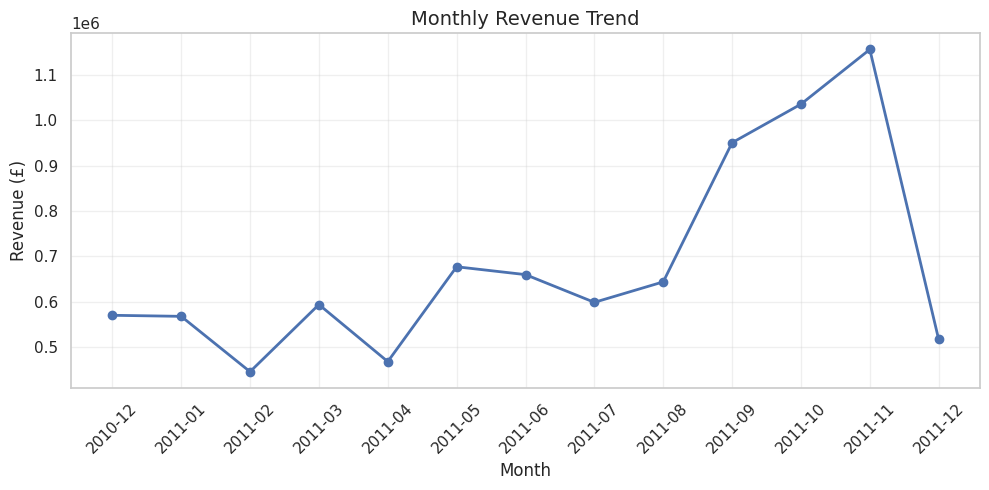

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values,
         marker='o', linewidth=2)

plt.title("Monthly Revenue Trend", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("chart1_monthly_revenue.png", dpi=300, bbox_inches="tight")
plt.show()

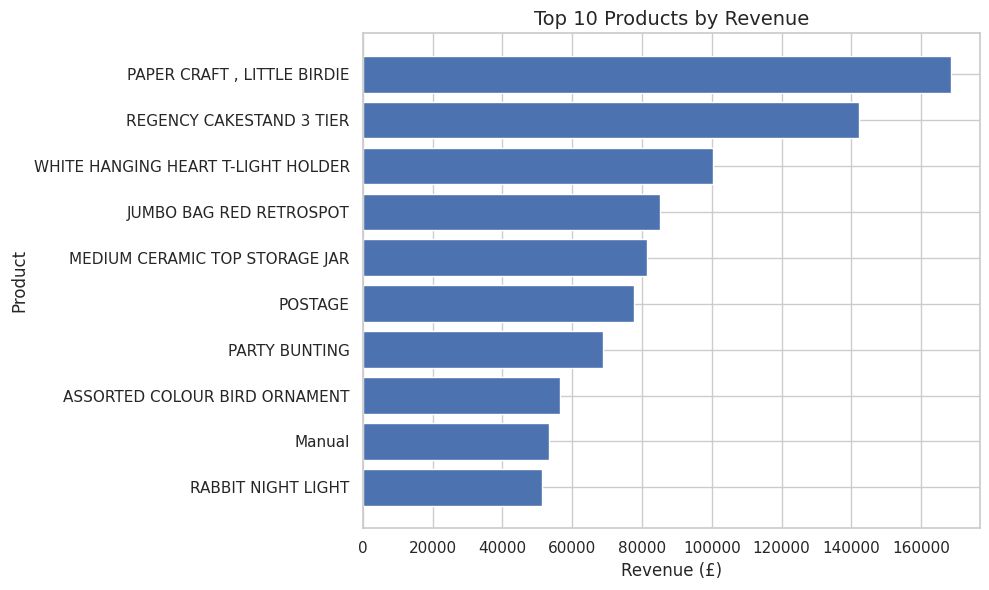

In [7]:
plt.figure(figsize=(10, 6))

plt.barh(top_products.index[::-1], top_products.values[::-1])

plt.title("Top 10 Products by Revenue", fontsize=14)
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.savefig("chart2_top_products.png", dpi=300, bbox_inches="tight")
plt.show()

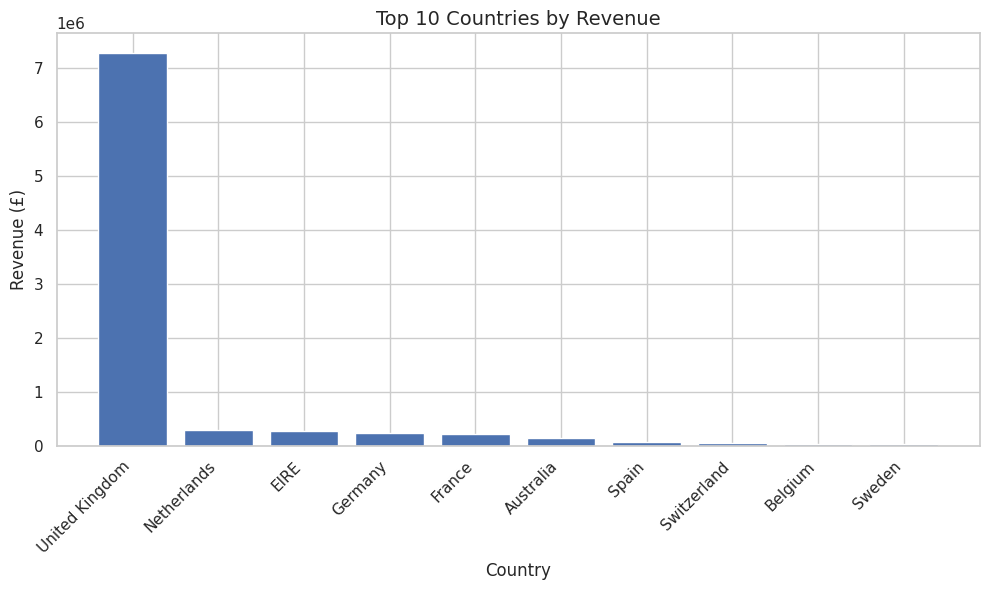

In [8]:
plt.figure(figsize=(10, 6))

plt.bar(country_sales.index, country_sales.values)

plt.title("Top 10 Countries by Revenue", fontsize=14)
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig("chart3_country_revenue.png", dpi=300, bbox_inches="tight")
plt.show()

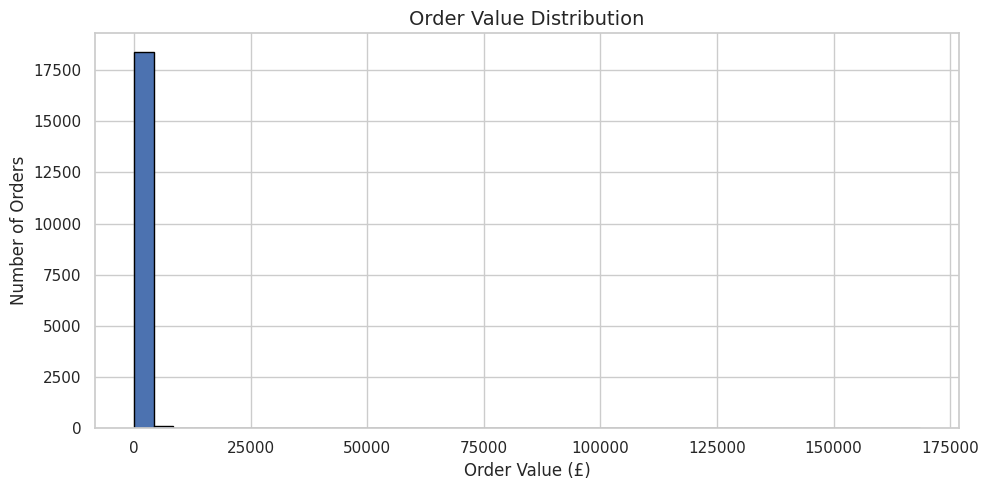

In [9]:
plt.figure(figsize=(10, 5))

plt.hist(order_values, bins=40, edgecolor='black')

plt.title("Order Value Distribution", fontsize=14)
plt.xlabel("Order Value (£)")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.savefig("chart4_order_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

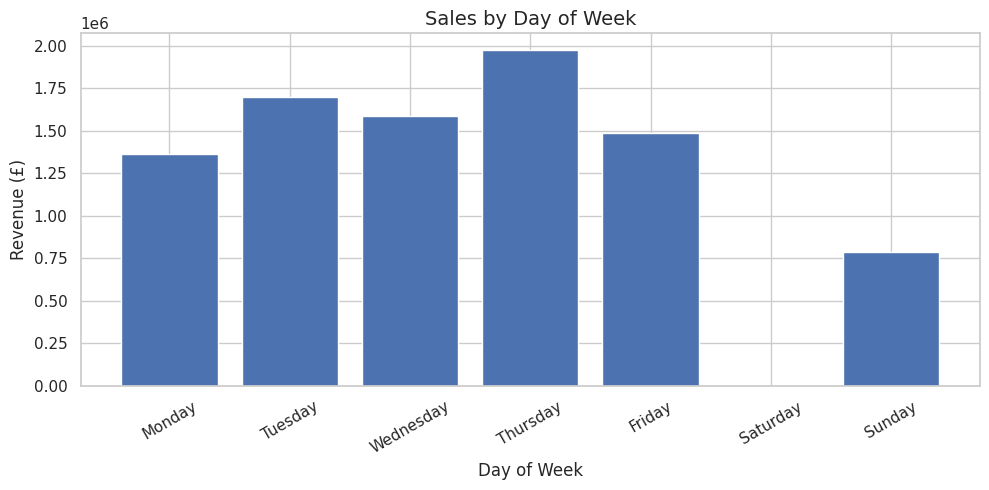

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(daily_sales.index, daily_sales.values)

plt.title("Sales by Day of Week", fontsize=14)
plt.xlabel("Day of Week")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("chart5_daily_sales.png", dpi=300, bbox_inches="tight")
plt.show()